# Índice de precios de alimentos: Productos básicos total (FAO)

Análisis de la serie mensual **Productos básicos total**, del índice de precios de alimentos de la FAO. El archivo entregado contiene observaciones desde enero de 2010 hasta agosto de 2026. La hoja `Metadatos` señala que la serie original tiene como primera observación enero de 1990; sin embargo, el archivo de datos de esta tarea comienza en 2010.

**Antes de ejecutar:** en Google Colab, cambiar el entorno a R y subir el archivo `EI_PROD_BAS_AL (Productos basicos total).xlsx` al panel de archivos. Luego ejecutar todas las celdas en orden.


## 1. Paquetes

In [17]:
paquetes <- c("readxl", "dplyr", "ggplot2", "scales", "tidyr")
faltan <- paquetes[!paquetes %in% rownames(installed.packages())]
if (length(faltan) > 0) install.packages(faltan)

suppressPackageStartupMessages({
  library(readxl)
  library(dplyr)
  library(ggplot2)
  library(scales)
  library(tidyr)
})


## 2. Revisión de la serie antes de programar

- **Frecuencia:** mensual.
- **Unidad:** índice de precios, con período base 2014–2016 = 100.
- **Fuente:** Organización de las Naciones Unidas para la Alimentación y la Agricultura (FAO).
- **Período disponible en este archivo:** enero de 2010 a agosto de 2026.
- **Código de serie:** `F019.PPBA.INP.46T.M`.

El índice no es una tasa porcentual: un valor de 133,3 significa que el nivel del índice está 33,3% por encima del nivel de referencia 2014–2016 = 100. No significa que los precios hayan subido 133,3% en el último año.


## 3. Lectura y limpieza de datos

En la hoja `Cuadro`, la fila 1 contiene el título, la fila 2 está vacía y los encabezados están en la fila 3. Por eso se usa `skip = 2`. El código busca el archivo por su nombre para evitar leer otro Excel que pudiera estar cargado en Colab.


In [18]:
archivo <- list.files(c("/content", "."), pattern = "EI_PROD_BAS_AL.*\\.xlsx$", full.names = TRUE)[1]
if (is.na(archivo)) stop("No encontré el archivo EI_PROD_BAS_AL. Súbelo al panel de archivos de Colab.")
cat("Leyendo:", archivo, "\n")

raw <- read_excel(archivo, sheet = "Cuadro", skip = 2)

df <- raw |>
  select(fecha = 1, indice = 2) |>
  mutate(
    fecha = as.Date(fecha),
    indice = as.numeric(indice)
  ) |>
  filter(!is.na(fecha), !is.na(indice)) |>
  arrange(fecha) |>
  mutate(
    anio = as.integer(format(fecha, "%Y")),
    mes = as.integer(format(fecha, "%m")),
    media_12m = as.numeric(stats::filter(indice, rep(1/12, 12), sides = 1)),
    var_12m = (indice / lag(indice, 12) - 1) * 100
  )

cat("Número de observaciones:", nrow(df), "\n")
cat("Primera fecha:", format(min(df$fecha), "%Y-%m"), "\n")
cat("Última fecha:", format(max(df$fecha), "%Y-%m"), "\n")
summary(df$indice)
tail(df, 12)


Leyendo: ./EI_PROD_BAS_AL (Productos basicos total).xlsx 
Número de observaciones: 200 
Primera fecha: 2010-01 
Última fecha: 2026-08 


   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
  84.93   96.64  118.83  113.90  126.06  160.22 

fecha,indice,anio,mes,media_12m,var_12m
<date>,<dbl>,<int>,<int>,<dbl>,<dbl>
2025-09-01,128.5688,2025,9,127.6684,3.1938249
2025-10-01,126.4229,2025,10,127.6304,-0.3594374
2025-11-01,125.2217,2025,11,127.4248,-1.9319113
2025-12-01,124.5054,2025,12,127.1916,-2.1978987
2026-01-01,124.1281,2026,1,127.1506,-0.3946729
2026-02-01,125.4743,2026,2,127.0567,-0.8902375
2026-03-01,128.6695,2026,3,127.1763,1.1274827
2026-04-01,131.0072,2026,4,127.4131,2.2177727
2026-05-01,131.0074,2026,5,127.7403,3.0895187


### ¿Por qué se calcula así la variación en 12 meses?

La variable es un **índice**, no una tasa expresada en porcentaje. Por eso calculamos la variación relativa respecto del mismo mes del año anterior:

$$\text{Variación 12m}_t = \left(\frac{\text{Índice}_t}{\text{Índice}_{t-12}} - 1\right) \times 100$$

El resultado indica el cambio porcentual del índice en los últimos doce meses. Por ejemplo, un resultado de 5% significa que el índice está 5% por encima de su valor de hace un año. No corresponde restar simplemente los índices ni expresar la diferencia en puntos porcentuales.

## 4. Estilo común para los gráficos

In [19]:
meses_es <- c("Ene", "Feb", "Mar", "Abr", "May", "Jun",
              "Jul", "Ago", "Sep", "Oct", "Nov", "Dic")
etq_fecha <- function(x) paste0(meses_es[as.integer(format(x, "%m"))], " ",
                                format(x, "%Y"))
num_es <- function(x) number(x, accuracy = 0.1, decimal.mark = ",")

col_principal <- "#1F4E79"
col_acento <- "#E07B39"

tema <- theme_minimal(base_size = 13) +
  theme(
    plot.title = element_text(face = "bold", size = 19, colour = "#1A1A1A"),
    plot.subtitle = element_text(colour = "#555555", margin = margin(b = 12)),
    plot.caption = element_text(colour = "#777777", size = 9, hjust = 0),
    plot.title.position = "plot",
    plot.caption.position = "plot",
    panel.grid.minor = element_blank(),
    panel.grid.major.x = element_blank(),
    panel.grid.major.y = element_line(colour = "#E5E5E5"),
    legend.position = "top",
    legend.justification = "left",
    plot.background = element_rect(fill = "white", colour = NA),
    plot.margin = margin(15, 24, 10, 15)
  )

fuente <- paste0(
  "Fuente: FAO, Índice de precios de alimentos. Serie F019.PPBA.INP.46T.M. ",
  "Unidad: índice (2014–2016 = 100)."
)


## 5. Evolución del índice y promedio móvil

La línea discontinua muestra el promedio móvil de 12 meses, que suaviza fluctuaciones de corto plazo. Se destacan el máximo, el mínimo y el dato más reciente. La anotación de 2022 marca un período de fuerte presión en los mercados internacionales de alimentos.


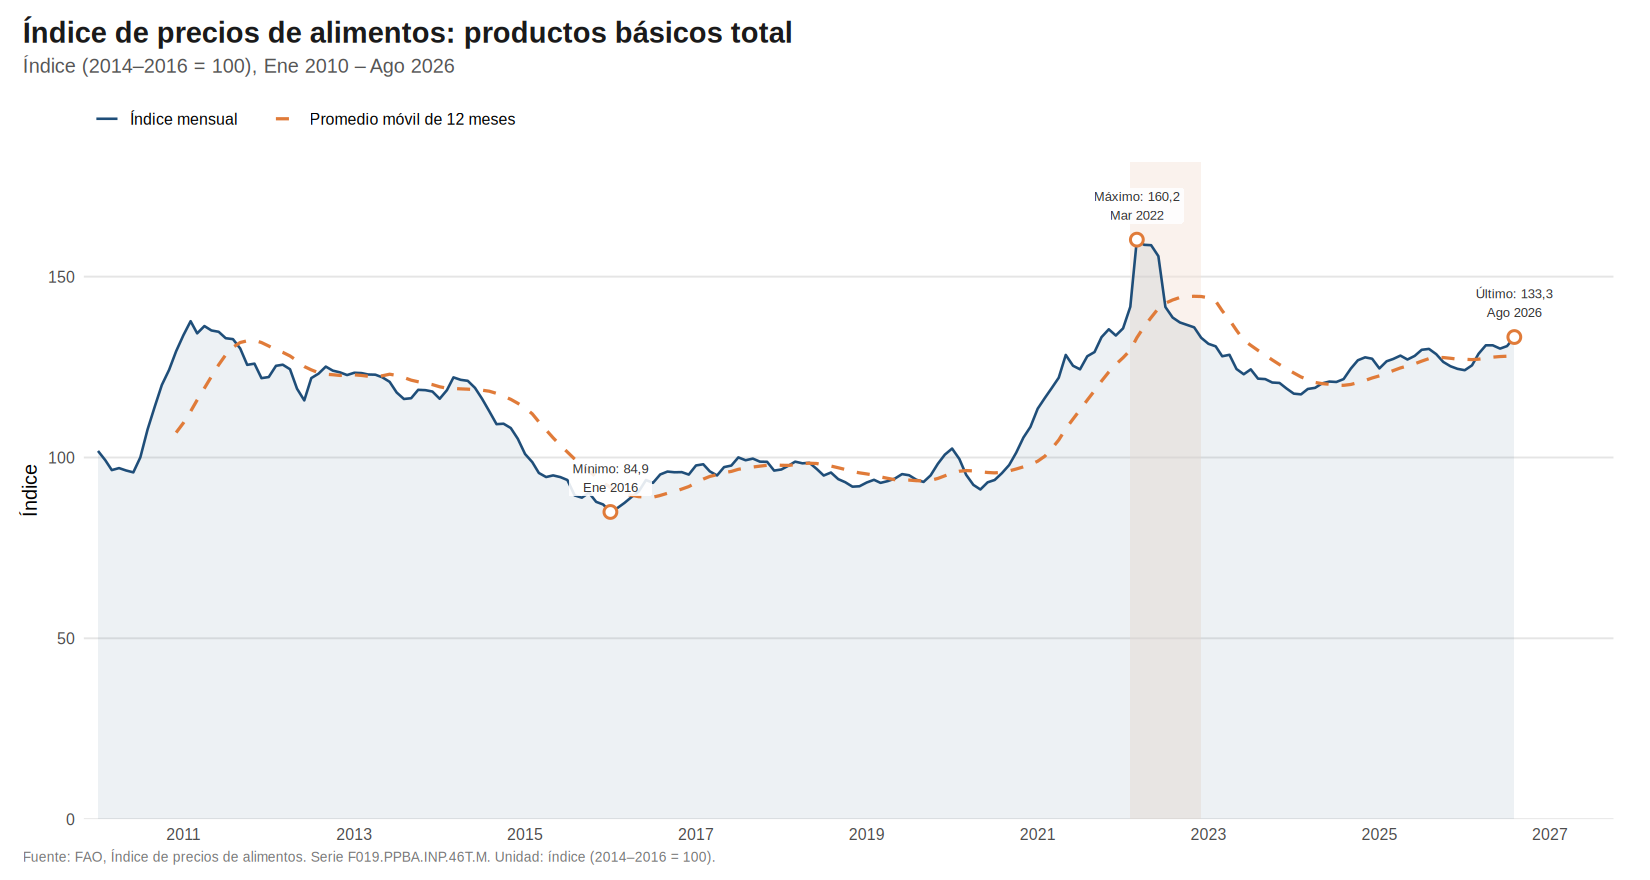

In [20]:
options(repr.plot.width = 15, repr.plot.height = 8, repr.plot.res = 110)

hitos <- bind_rows(
  df |> slice_max(indice, n = 1, with_ties = FALSE) |> mutate(txt = paste0("Máximo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_min(indice, n = 1, with_ties = FALSE) |> mutate(txt = paste0("Mínimo: ", num_es(indice), "\n", etq_fecha(fecha))),
  df |> slice_tail(n = 1) |> mutate(txt = paste0("Último: ", num_es(indice), "\n", etq_fecha(fecha)))
)

g1 <- ggplot(df, aes(x = fecha)) +
  annotate("rect", xmin = as.Date("2022-02-01"), xmax = as.Date("2022-12-01"),
           ymin = -Inf, ymax = Inf, fill = "#F3E3D8", alpha = 0.45) +
  geom_area(aes(y = indice), fill = col_principal, alpha = 0.08) +
  geom_line(aes(y = indice, colour = "Índice mensual"), linewidth = 0.8) +
  geom_line(aes(y = media_12m, colour = "Promedio móvil de 12 meses"),
            linewidth = 1, linetype = "dashed", na.rm = TRUE) +
  geom_point(data = hitos, aes(y = indice), size = 3,
             colour = col_acento, fill = "white", shape = 21, stroke = 1.4) +
  geom_label(data = hitos, aes(y = indice, label = txt), size = 3,
             vjust = -0.45, linewidth = 0, fill = alpha("white", 0.88),
             colour = "#333333", show.legend = FALSE) +
  scale_colour_manual(NULL, values = c("Índice mensual" = col_principal,
                                       "Promedio móvil de 12 meses" = col_acento)) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y",
               expand = expansion(mult = c(0.01, 0.07))) +
  scale_y_continuous(labels = label_number(accuracy = 1, decimal.mark = ","),
                     limits = c(0, max(df$indice, na.rm = TRUE) + 18),
                     expand = expansion(mult = c(0, 0.02))) +
  labs(
    title = "Índice de precios de alimentos: productos básicos total",
    subtitle = paste0("Índice (2014–2016 = 100), ", etq_fecha(min(df$fecha)),
                      " – ", etq_fecha(max(df$fecha))),
    x = NULL, y = "Índice", caption = fuente
  ) +
  tema

g1


## 6. Mapa de calor por año y mes

Cada celda representa el nivel del índice en un mes. Los tonos más oscuros corresponden a valores más altos. El color del texto se adapta al valor respecto del promedio de toda la muestra, para mantener la legibilidad.


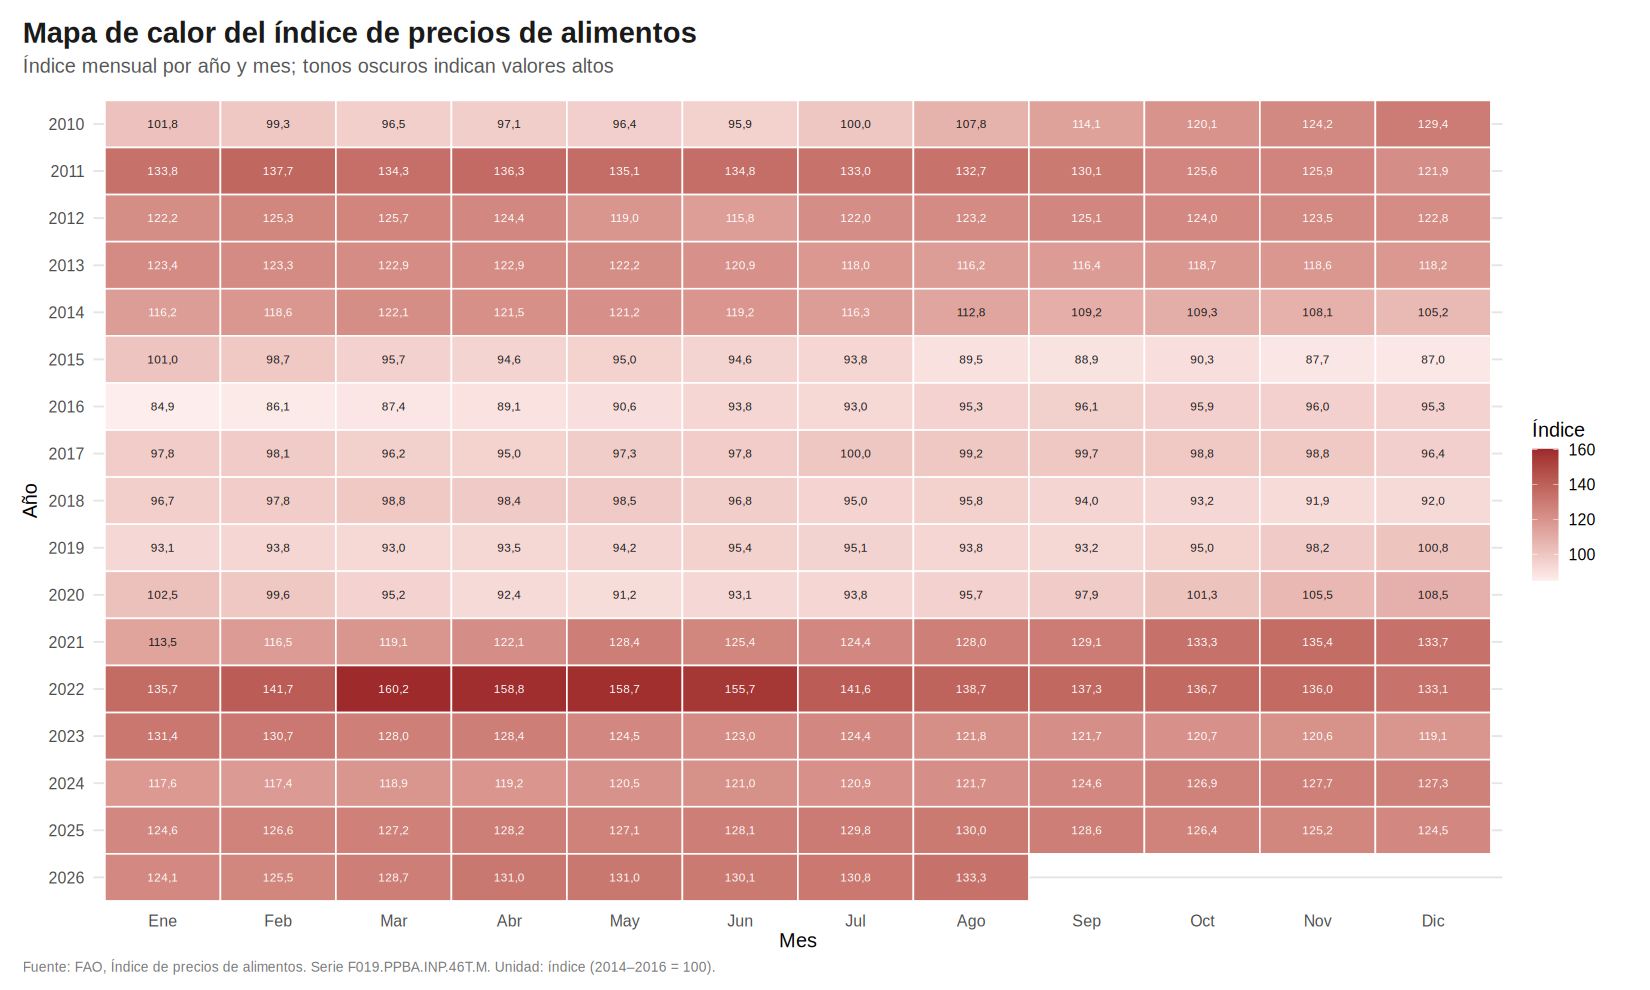

In [21]:
options(repr.plot.width = 15, repr.plot.height = 9)

umbral_color <- mean(df$indice, na.rm = TRUE)

g2 <- ggplot(df, aes(
  x = factor(mes, levels = 1:12, labels = meses_es),
  y = factor(anio, levels = rev(sort(unique(anio)))),
  fill = indice
)) +
  geom_tile(colour = "white", linewidth = 0.5) +
  geom_text(aes(label = num_es(indice),
                colour = indice > umbral_color),
            size = 2.7, show.legend = FALSE) +
  scale_colour_manual(values = c(`TRUE` = "white", `FALSE` = "#1A1A1A")) +
  scale_fill_gradient(low = "#FDEDEC", high = "#9E2A2B",
                      name = "Índice") +
  labs(
    title = "Mapa de calor del índice de precios de alimentos",
    subtitle = "Índice mensual por año y mes; tonos oscuros indican valores altos",
    x = "Mes", y = "Año", caption = fuente
  ) +
  tema +
  theme(panel.grid = element_blank(), legend.position = "right")

g2


## 7. Variación porcentual en 12 meses

Las barras muestran cuánto cambió el índice respecto del mismo mes del año anterior. Valores positivos indican que el índice está más alto que hace doce meses; valores negativos, que está más bajo.


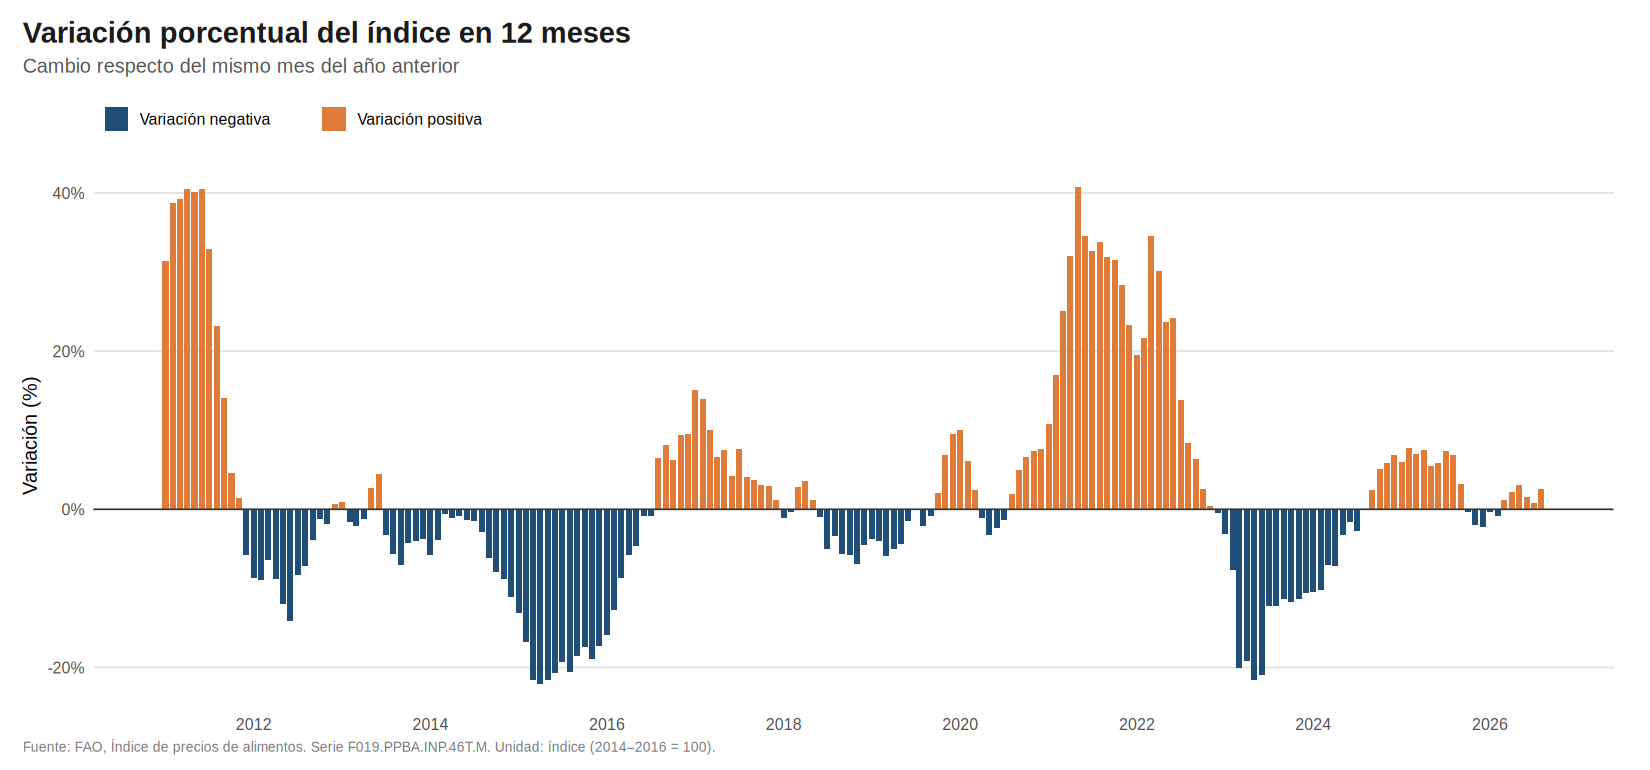

In [22]:
options(repr.plot.width = 15, repr.plot.height = 7)

g3 <- df |>
  filter(!is.na(var_12m)) |>
  ggplot(aes(x = fecha, y = var_12m, fill = var_12m > 0)) +
  geom_col(width = 25) +
  geom_hline(yintercept = 0, colour = "#333333", linewidth = 0.5) +
  scale_fill_manual(
    values = c(`TRUE` = col_acento, `FALSE` = col_principal),
    labels = c(`TRUE` = "Variación positiva", `FALSE` = "Variación negativa"),
    name = NULL
  ) +
  scale_x_date(date_breaks = "2 years", date_labels = "%Y") +
  scale_y_continuous(labels = label_number(accuracy = 1, suffix = "%", decimal.mark = ",")) +
  labs(
    title = "Variación porcentual del índice en 12 meses",
    subtitle = "Cambio respecto del mismo mes del año anterior",
    x = NULL, y = "Variación (%)", caption = fuente
  ) +
  tema

g3


## 8. Interpretación económica

En el período disponible, el índice de precios de los productos básicos alimentarios promedia aproximadamente **113,9 puntos**, considerando la base 2014–2016 = 100. El último dato, agosto de 2026, alcanza **133,3 puntos**, es decir, se ubica alrededor de **19,4 puntos por encima del promedio de la muestra**. Esto indica que el nivel del índice al final del período es relativamente elevado en comparación con su trayectoria completa, aunque el índice por sí solo no mide el costo de vida de un hogar específico.

El máximo de la serie ocurre en **marzo de 2022**, con aproximadamente **160,2 puntos**. Este aumento coincide con la fuerte perturbación de los mercados internacionales de alimentos tras la invasión rusa de Ucrania, que afectó especialmente las exportaciones de cereales y aceites vegetales desde la región del mar Negro. La FAO informó que su índice mundial de precios de alimentos alcanzó un récord en marzo de 2022, impulsado por estas interrupciones comerciales y alzas de precios. Esta coincidencia ofrece una explicación económica plausible, aunque no demuestra que un solo evento explique toda la variación de la serie. (FAO, 2022: https://www.fao.org/newsroom/detail/fao-food-price-index-posts-significant-leap-in-march/en)

El mínimo del período disponible se registra en **enero de 2016**, con aproximadamente **84,9 puntos**. La debilidad de los precios internacionales de alimentos en torno a ese momento es consistente con las explicaciones de la FAO sobre abundantes suministros agrícolas, menor dinamismo de la economía mundial y fortalecimiento del dólar. (FAO, 2016: https://www.fao.org/newsroom/detail/FAO-Food-Price-Index-starts-2016-dropping-to-nearly-7-year-low/it)

El mapa de calor debe interpretarse con cautela: los niveles mensuales promedio son relativamente parecidos y no muestran por sí solos una estacionalidad marcada. La variación interanual permite complementar esa lectura. En agosto de 2026, el índice está aproximadamente **2,5% por encima** de agosto de 2025. Además, después de variaciones interanuales negativas entre octubre de 2025 y febrero de 2026, los registros vuelven a ser positivos desde marzo de 2026. Esto sugiere una recuperación reciente del índice respecto del año anterior, pero no necesariamente un retorno al máximo de 2022. La conclusión debe revisarse junto con los tres gráficos una vez ejecutado el notebook.


## 9. Guardar los gráficos en PNG

Los archivos PNG se guardan en el entorno de Colab y se pueden descargar desde el panel de archivos.


In [23]:
ggsave("productos_basicos_serie.png", g1, width = 12, height = 6.5, dpi = 300)
ggsave("productos_basicos_mapa_calor.png", g2, width = 11, height = 8, dpi = 300)
ggsave("productos_basicos_variacion12m.png", g3, width = 12, height = 5.5, dpi = 300)

list.files(pattern = "productos_basicos.*\\.png$")


[1] "productos_basicos_mapa_calor.png"   "productos_basicos_serie.png"       
[3] "productos_basicos_variacion12m.png"